# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


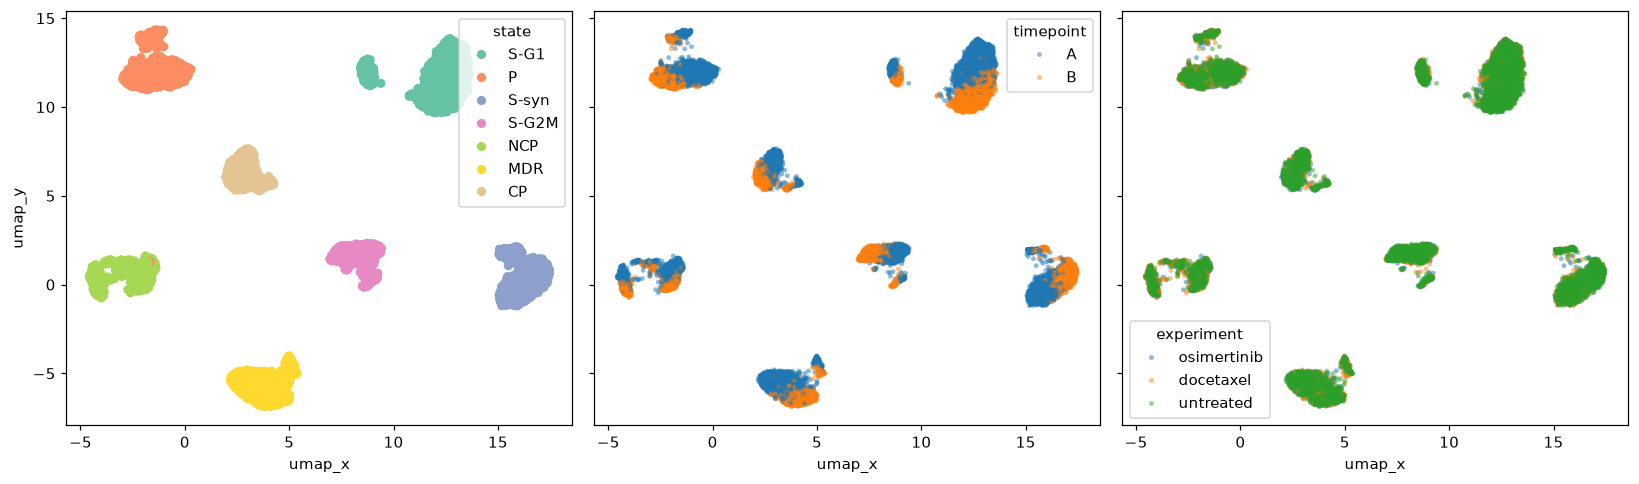

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

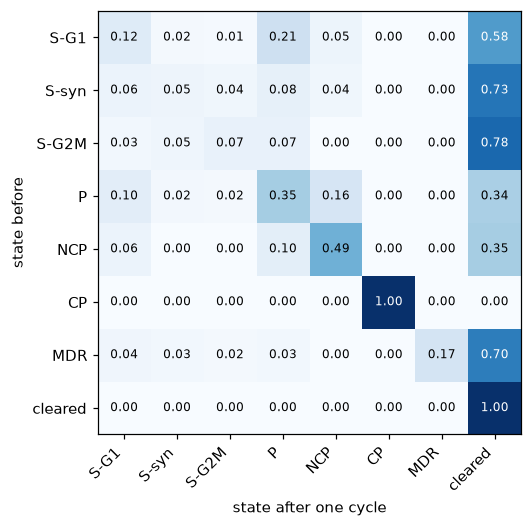

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

The closest states to an absorbing distinction are CP to CP (this is the only other state that has probability 1), NCP to NCP (.49), and P to P (.35).  CP is clearly the standout here, and it means that the state CP isn't affected at all by the drug treatment.  Everything else is affected at least to some degree by the treatment, with the other high absorbing distinction states being the least affected.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

s-sym and S-G2M are both incredibly low after a round, though not completely 0.  SG-1 is also quite low.  The rest seem to have some sort of sticking power.

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

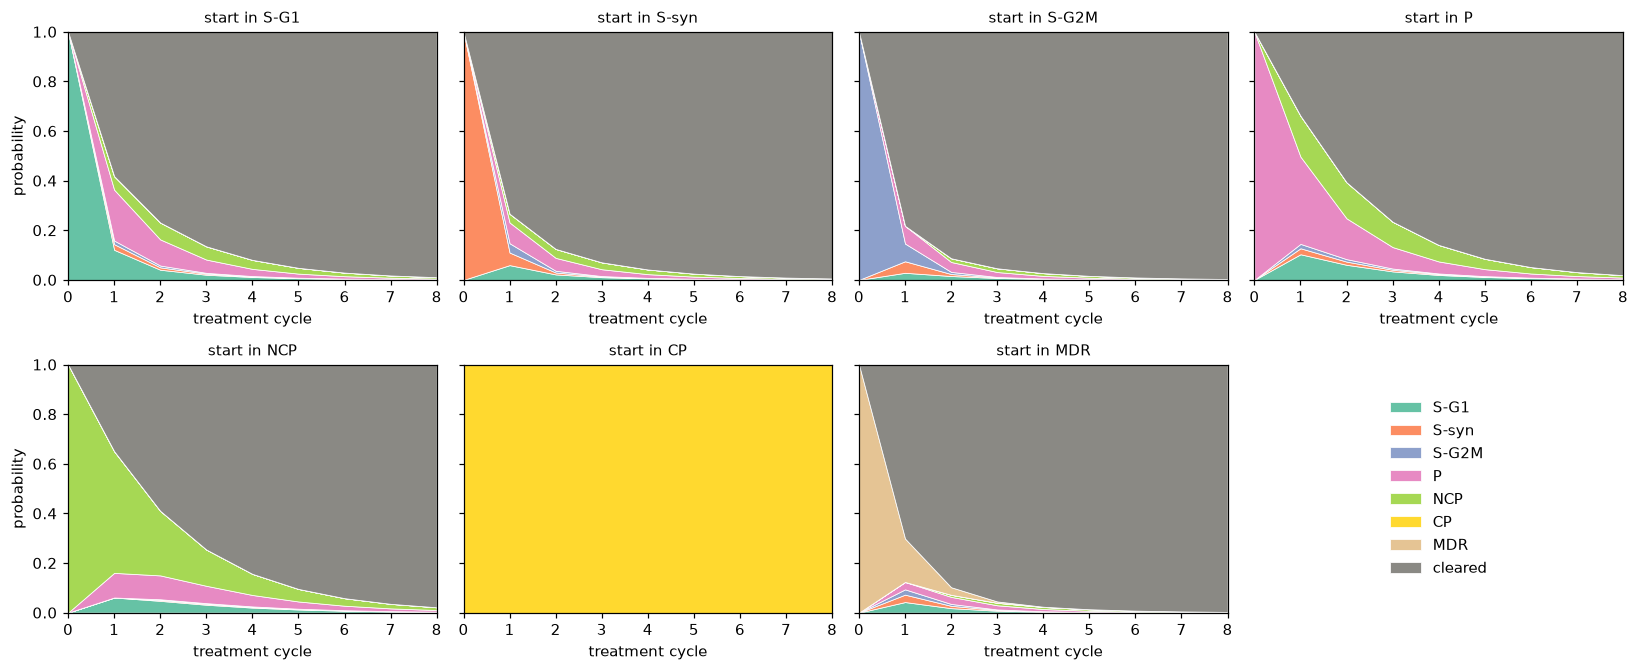

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [17]:
P = P_hat.to_numpy()
cleared_idx = OUTCOMES.index("cleared")

P_inf = pd.DataFrame(np.linalg.matrix_power(P, 500), index=OUTCOMES, columns=OUTCOMES)
print("Probability of ending in 'cleared':")
print(P_inf.loc[STATES, "cleared"].round(4))

Probability of ending in 'cleared':
S-G1     1.0
S-syn    1.0
S-G2M    1.0
P        1.0
NCP      1.0
CP       0.0
MDR      1.0
Name: cleared, dtype: float64


Seems like every state besides CP ultimately ends in cleared with enough treatments.

In [18]:
clearable = [s for s in STATES if s != "CP"]
idx = [OUTCOMES.index(s) for s in clearable]
Q = P[np.ix_(idx, idx)]
N = np.linalg.inv(np.eye(len(idx)) - Q)              # N[i,j] = expected visits to j starting from i
exp_cycles = pd.Series(N.sum(axis=1), index=clearable).sort_values(ascending=False)
print("\nExpected cycles alive before clearance:")
print(exp_cycles.round(3))


Expected cycles alive before clearance:
NCP      2.716
P        2.647
S-G1     1.988
S-syn    1.568
MDR      1.504
S-G2M    1.420
dtype: float64


NCP and P comfortably last the longest, with the rest lagging behind.  In theory CP lasts the longest since it doesn't get cleared, but of the clearable states NCP is the longest.

In [19]:
alive3 = pd.Series({s: 1 - evolve(basis(s, P_hat), P, 3)[-1, cleared_idx] for s in STATES})
print("\nFraction alive after 3 cycles:")
print(alive3.sort_values(ascending=False).round(3))


Fraction alive after 3 cycles:
CP       1.000
NCP      0.254
P        0.234
S-G1     0.135
S-syn    0.071
S-G2M    0.047
MDR      0.045
dtype: float64


CP has by far the highest proportion, and it's at 100% because it isn't cleared in the previous data.  Outside of CP, it's NCP and P with by far the highest proportions.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

S-G1       0.247
S-syn      0.148
S-G2M      0.099
P          0.153
NCP        0.102
CP         0.097
MDR        0.153
cleared    0.000
dtype: float64


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


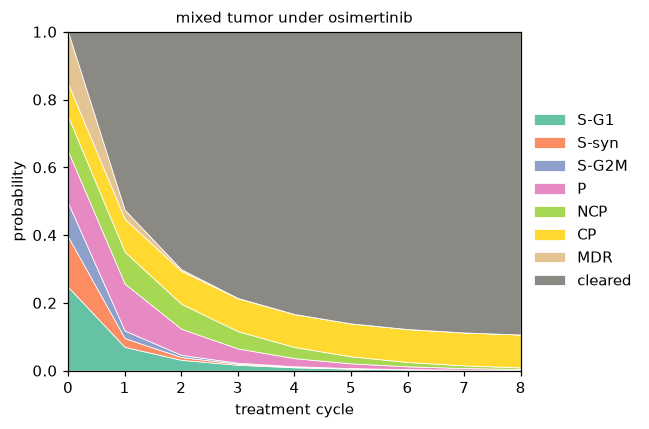

In [20]:
A_cells = cells[cells["timepoint"] == "A"]
pi_mix = (A_cells["state"]
          .value_counts(normalize=True)
          .reindex(OUTCOMES, fill_value=0)
          .to_numpy())

assert np.isclose(pi_mix.sum(), 1) and len(pi_mix) == len(OUTCOMES)
print(pd.Series(pi_mix, index=OUTCOMES).round(3))

traj_mix = evolve(pi_mix, P_hat, N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_mix, ax, "mixed tumor under osimertinib")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP clearly dominates the end cluster, with just a hint of NCP and maybe P visible as well.  It flattens out tremendously, which means that it doesn't seem likely these cells will every be cleared.  At the very least, it would require a large amount of treatment cycles, which isn't great with chemotherapy generally.

As for the endpoint and matrix, the endpoint is a distribution of the transition matrix.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [23]:
def build_P(experiment):
    sub = cells[cells["experiment"] == experiment]
    at_A = sub[sub.timepoint == "A"][["lineage_tag", "state"]]
    at_B = sub[sub.timepoint == "B"][["lineage_tag", "state"]]
    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["state_B"] = pairs["state_B"].fillna("cleared")

    counts = (pd.crosstab(pairs.state_A, pairs.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = counts.div(counts.sum(axis=1), axis=0)
    P.loc["cleared"] = [1 if c == "cleared" else 0 for c in P.columns]
    assert np.allclose(P.sum(axis=1), 1), "rows must sum to 1 (a state with 0 cells at A gives NaN)"
    return P

P_doc_df     = build_P("docetaxel")
P_holiday_df = build_P("untreated")

P_osi     = P_hat.to_numpy()
P_doc     = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()

# check for absorbing / near-absorbing states
for name, P in [("osimertinib", P_osi), ("docetaxel", P_doc), ("holiday", P_holiday)]:
    diag = pd.Series(np.diag(P), index=OUTCOMES)
    print(name, "absorbing / near-absorbing:", list(diag[diag > 0.95].index))

osimertinib absorbing / near-absorbing: ['CP', 'cleared']
docetaxel absorbing / near-absorbing: ['MDR', 'cleared']
holiday absorbing / near-absorbing: ['cleared']


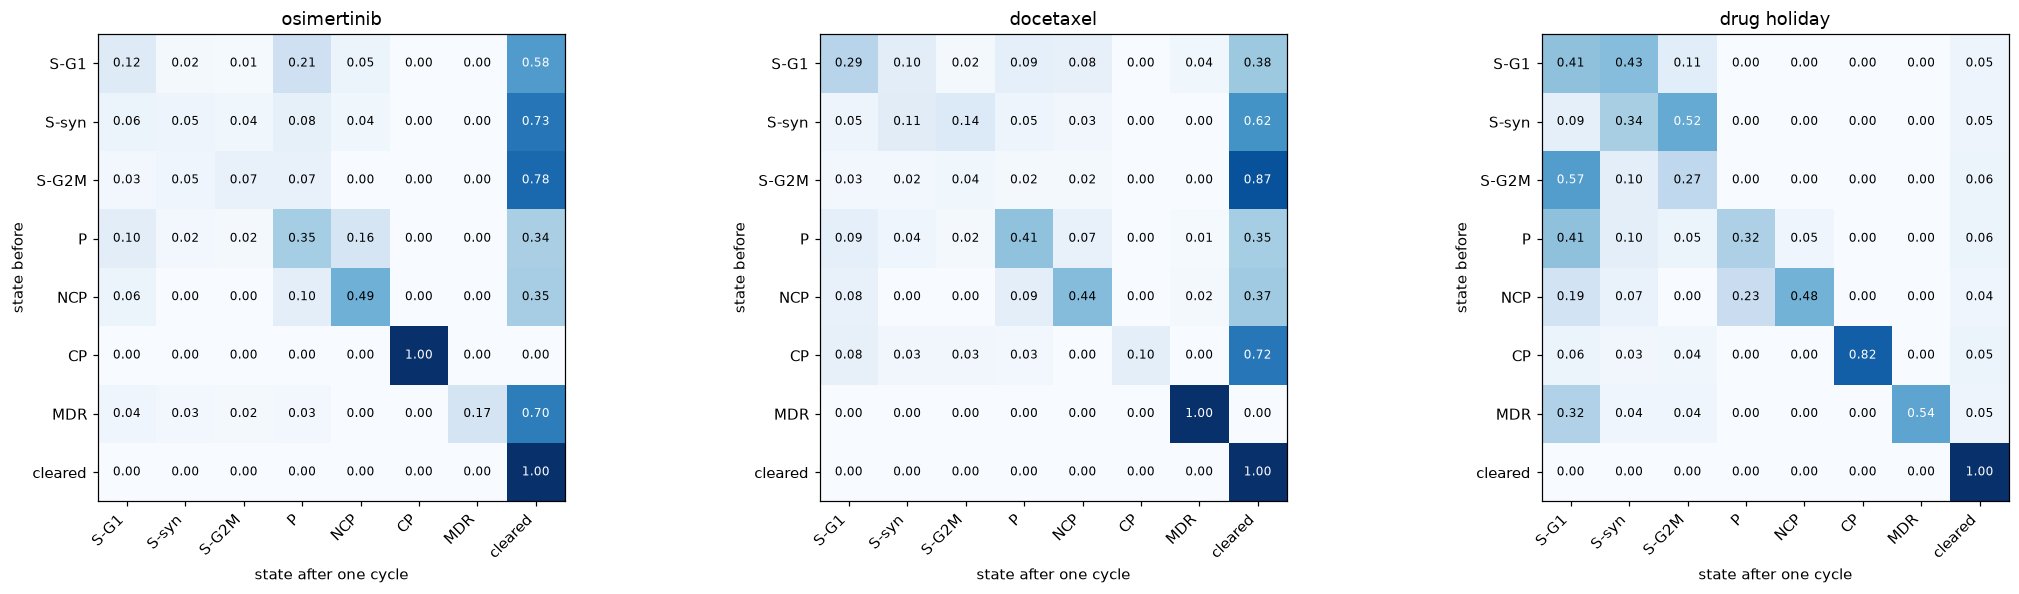

In [24]:
#Plot the transition matrices for docetaxel and the drug holiday.

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
show_matrix(P_hat,        "osimertinib", ax=axes[0])
show_matrix(P_doc_df,     "docetaxel",   ax=axes[1])
show_matrix(P_holiday_df, "drug holiday", ax=axes[2])
plt.tight_layout()
plt.show()

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


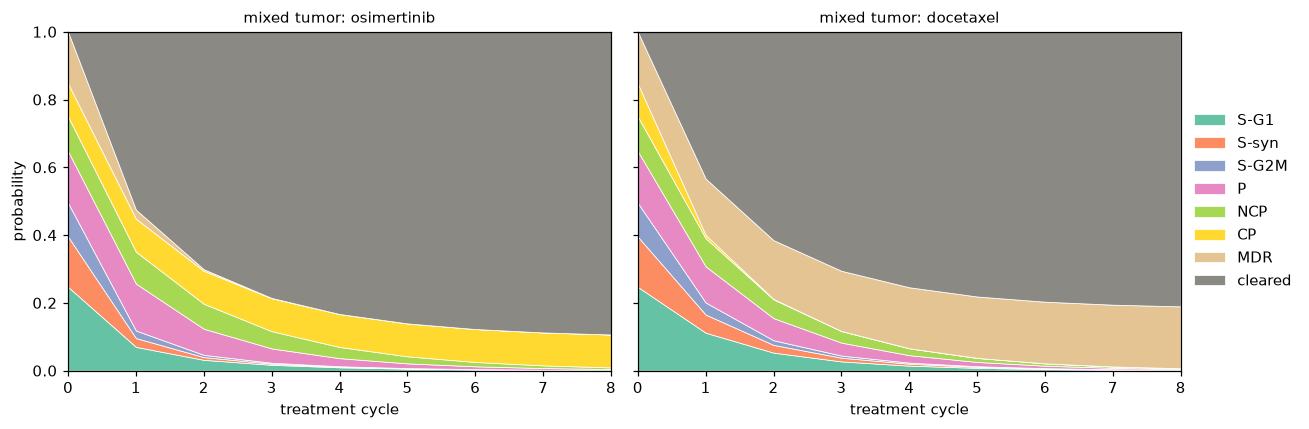

fraction alive after 8 cycles of docetaxel: 0.19
remaining mass by state:
S-G1       0.002
S-syn      0.001
S-G2M      0.000
P          0.002
NCP        0.002
CP         0.000
MDR        0.183
cleared    0.810
dtype: float64


In [25]:
# Simulate the evolution of pi_mix under docetaxel

traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plot_trajectory(evolve(pi_mix, P_osi, N_CYCLES), axes[0], "mixed tumor: osimertinib")
plot_trajectory(traj_doc,                        axes[1], "mixed tumor: docetaxel")
axes[0].set_ylabel("probability")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

print("fraction alive after 8 cycles of docetaxel:", round(1 - traj_doc[-1, -1], 3))
print("remaining mass by state:")
print(pd.Series(traj_doc[-1], index=OUTCOMES).round(3))

The matrix under docetaxel looks remarkably similar to the osimertinib matrix, with similar results and similar absorbing states.  There is one major difference though, which is that osimertinib has CP to CP at 1.00 and MDR to MDR at .17, while docetaxel is basically the opposite at CP .1 and MDR 1.00.  Even the absorbing states are the same.

Under multiple rounds, cleared reaches .810.  There's really only one state that remains not cleared, and that's MDR.  This makes sense with the transition matrix, as MDR is the state that doesn't change in the matrix at all.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [26]:
ci = OUTCOMES.index("cleared")
MATS = {"osi": P_osi, "doc": P_doc, "hol": P_holiday}

def run_schedule(pi0, schedule, mats=MATS):
    '''schedule = list of drug names, one per cycle, e.g. ["osi","doc"]*4.
    Returns array (len(schedule)+1, n_states) of distributions.'''
    traj = [np.asarray(pi0, float)]
    for d in schedule:
        traj.append(traj[-1] @ mats[d])
    return np.array(traj)

def alive(traj):
    return 1 - traj[:, ci]

N = 8
schedules = {
    "8x osi":           ["osi"] * N,
    "8x doc":           ["doc"] * N,
    "alternate osi→doc": ["osi", "doc"] * (N // 2),   # = (P_osi @ P_doc)^4
    "alternate doc→osi": ["doc", "osi"] * (N // 2),   # = (P_doc @ P_osi)^4
}

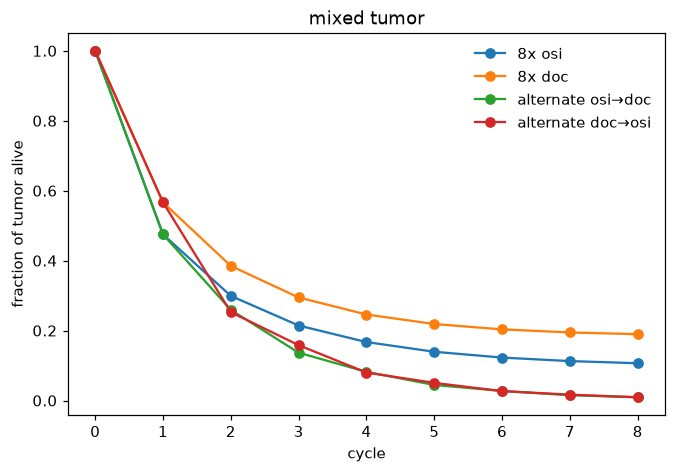

,alive after 8,CP remaining
8x osi,0.1066,0.0972
8x doc,0.1896,0.0000
alternate osi→doc,0.0094,0.0000
alternate doc→osi,0.0092,0.0000


P_osi@P_doc == P_doc@P_osi ? False
         osi first  doc first
S-G1        0.0016     0.0014
S-syn       0.0005     0.0003
S-G2M       0.0003     0.0002
P           0.0030     0.0031
NCP         0.0033     0.0038
CP          0.0000     0.0000
MDR         0.0007     0.0003
cleared     0.9906     0.9908
alive gap (osi-first vs doc-first) by starting state:
S-G1     0.0009
S-syn    0.0004
S-G2M    0.0011
P        0.0016
NCP      0.0017
CP       0.0028
MDR      0.0025
dtype: float64


In [27]:
fig, ax = plt.subplots(figsize=(7, 4.5))
summary = {}
for name, sched in schedules.items():
    traj = run_schedule(pi_mix, sched)
    ax.plot(range(N + 1), alive(traj), marker="o", label=name)
    summary[name] = {"alive after 8": alive(traj)[-1],
                     "CP remaining": traj[-1, OUTCOMES.index("CP")]}
ax.set_xlabel("cycle"); ax.set_ylabel("fraction of tumor alive")
ax.set_title("mixed tumor"); ax.legend(frameon=False)
plt.show()
display(pd.DataFrame(summary).T.round(4))

print("P_osi@P_doc == P_doc@P_osi ?", np.allclose(P_osi @ P_doc, P_doc @ P_osi))
a = run_schedule(pi_mix, schedules["alternate osi→doc"])[-1]
b = run_schedule(pi_mix, schedules["alternate doc→osi"])[-1]
print(pd.DataFrame({"osi first": a, "doc first": b}, index=OUTCOMES).round(4))

order_gap = pd.Series(
    {s: abs(alive(run_schedule(basis(s, P_hat), schedules["alternate osi→doc"]))[-1]
          - alive(run_schedule(basis(s, P_hat), schedules["alternate doc→osi"]))[-1])
     for s in STATES})
print("alive gap (osi-first vs doc-first) by starting state:")
print(order_gap.round(4))

In [28]:
holiday_schedules = {
    "8x osi (no holiday)":        ["osi"] * N,
    "osi, hol, osi, hol, ...":    ["osi", "hol"] * (N // 2),
    "osi x4, hol x4":             ["osi"] * 4 + ["hol"] * 4,
    "8x doc (no holiday)":        ["doc"] * N,
    "doc, hol, doc, hol, ...":    ["doc", "hol"] * (N // 2),
}

rows = {}
for s in STATES:
    pi0 = basis(s, P_hat)
    rows[s] = {name: alive(run_schedule(pi0, sch))[-1]
               for name, sch in holiday_schedules.items()}
display(pd.DataFrame(rows).T.round(4))

print("Mixed tumor after 1 cycle of osi:", pd.Series(pi_mix @ P_osi, OUTCOMES).round(3).to_dict())
print("... then 1 holiday cycle:        ", pd.Series(pi_mix @ P_osi @ P_holiday, OUTCOMES).round(3).to_dict())

,8x osi (no holiday),"osi, hol, osi, hol, ...","osi x4, hol x4",8x doc (no holiday),"doc, hol, doc, hol, ..."
S-G1,0.0108,0.0305,0.0653,0.0727,0.0662
S-syn,0.0056,0.0175,0.0340,0.0124,0.0326
S-G2M,0.0036,0.0125,0.0220,0.0059,0.0125
P,0.0190,0.0544,0.1142,0.0545,0.0769
NCP,0.0216,0.0675,0.1270,0.0681,0.0899
CP,1.0000,0.5682,0.8066,0.0101,0.0194
MDR,0.0029,0.0144,0.0192,1.0000,0.3107


Mixed tumor after 1 cycle of osi: {'S-G1': 0.07, 'S-syn': 0.026, 'S-G2M': 0.022, 'P': 0.139, 'NCP': 0.094, 'CP': 0.097, 'MDR': 0.027, 'cleared': 0.525}
... then 1 holiday cycle:         {'S-G1': 0.133, 'S-syn': 0.066, 'S-G2M': 0.039, 'P': 0.066, 'NCP': 0.051, 'CP': 0.08, 'MDR': 0.015, 'cleared': 0.55}


In [29]:
THRESH = 0.01
MAX = 30

candidates = {
    "osi":               lambda n: ["osi"] * n,
    "doc":               lambda n: ["doc"] * n,
    "alt osi→doc":       lambda n: (["osi", "doc"] * n)[:n],
    "alt doc→osi":       lambda n: (["doc", "osi"] * n)[:n],
}

def rounds_to_clear(pi0, make_sched, thresh=THRESH, max_n=MAX):
    for n in range(1, max_n + 1):
        if alive(run_schedule(pi0, make_sched(n)))[-1] <= thresh:
            return n
    return np.nan      # never gets there within max_n

starts = {s: basis(s, P_hat) for s in STATES}
starts["measured mix"] = pi_mix

table = pd.DataFrame({
    sched: {name: rounds_to_clear(pi0, f) for name, pi0 in starts.items()}
    for sched, f in candidates.items()
})
table["best"] = table.idxmin(axis=1)
table["fewest rounds"] = table.drop(columns="best").min(axis=1)
display(table)

four = pd.DataFrame({
    sched: {name: alive(run_schedule(pi0, f(4)))[-1] for name, pi0 in starts.items()}
    for sched, f in candidates.items()
})
display(four.round(3))

,osi,doc,alt osi→doc,alt doc→osi,best,fewest rounds
S-G1,9.0,NaN,8,9,alt osi→doc,8.0
S-syn,7.0,10.0,7,7,osi,7.0
S-G2M,6.0,6.0,6,6,osi,6.0
P,10.0,NaN,9,9,alt osi→doc,9.0
NCP,10.0,NaN,10,10,osi,10.0
CP,NaN,9.0,8,7,alt doc→osi,7.0
MDR,6.0,NaN,7,8,osi,6.0
measured mix,NaN,NaN,8,8,alt osi→doc,8.0


,osi,doc,alt osi→doc,alt doc→osi
S-G1,0.081,0.155,0.083,0.091
S-syn,0.042,0.045,0.043,0.040
S-G2M,0.027,0.020,0.027,0.017
P,0.141,0.160,0.141,0.128
NCP,0.156,0.178,0.152,0.139
CP,1.000,0.035,0.067,0.038
MDR,0.024,1.000,0.058,0.080
measured mix,0.167,0.246,0.082,0.080


1. The alternating schedules seems to be noticeably better than either drug individually.

2. No, the order doesn't seem to matter at all for the alternating schedule.  The results seem to be nearly identical.

3. The states that seem to be encouraged by the drugs are CP (for osi) and MDR (for doc), so introducing drug holidays would likely lower those states if the plan is to only use one drug or the other.

4. My thought is that fewer rounds of chemotherapy is better, so I'd like to find the most effective plan that also requires the least amount of rounds.  By that logic, I would recommend alternating doc and osi for six rounds, as that was the smallest number of rounds found in the table for that plan.  Looking at the above table, that seems like a good mix of effectiveness and fewer chemo rounds.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [30]:
rng = np.random.default_rng(100)

In [31]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [32]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

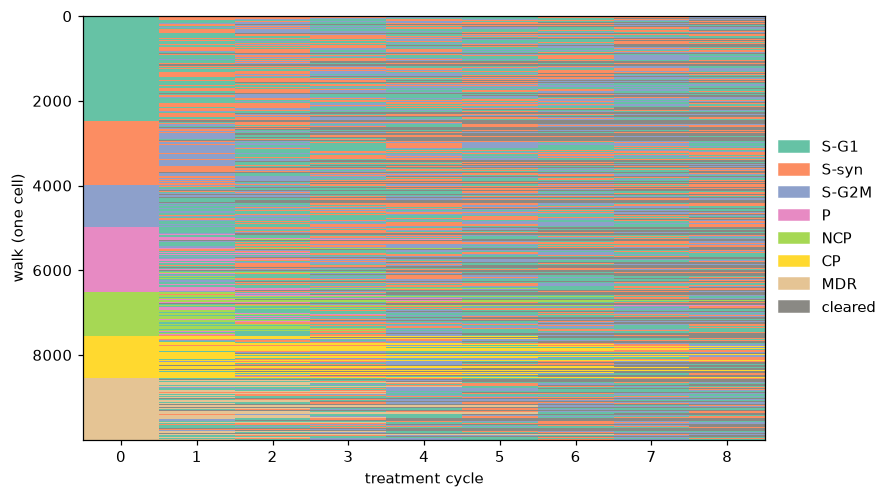

In [36]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [37]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

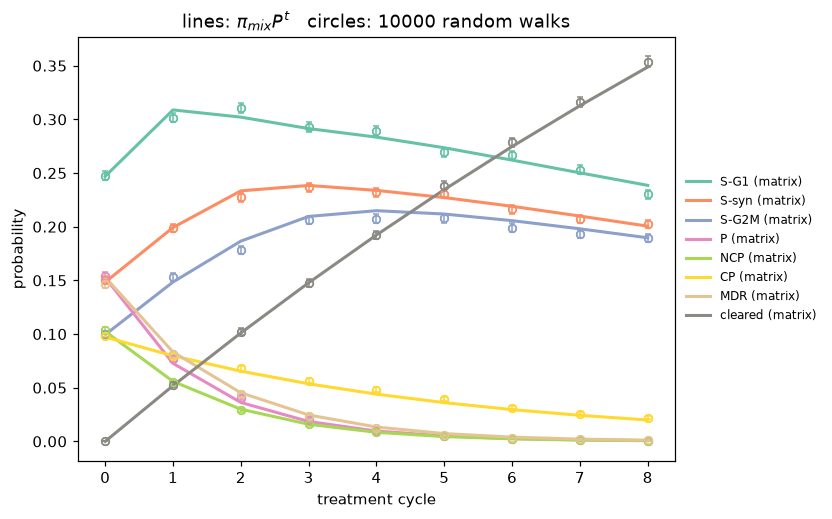

In [38]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

The lines almost entirely vanish.  I would assume this is because a larger sample size reduced variability, and in this case variability is directly represented by the gap between the circles and lines.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [39]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

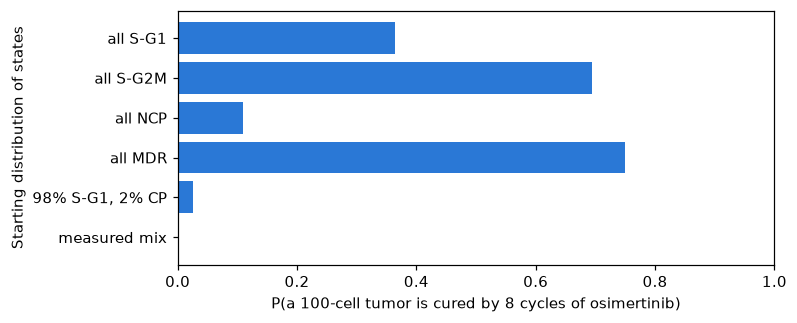

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [40]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

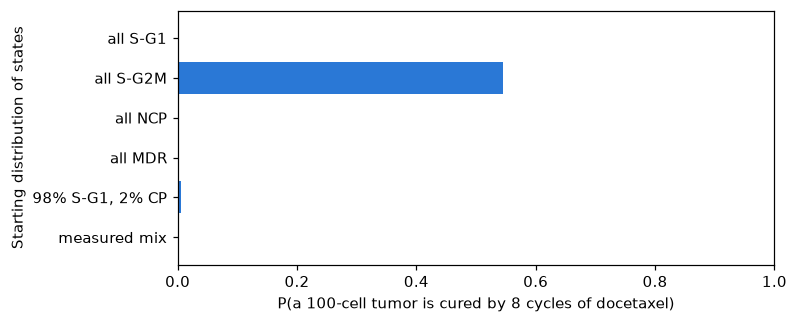

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.985,0.0
measured mix,0.000,18.955,0.0


In [41]:
N_CELLS, N_TUMORS = 100, 200
DRUG, P_TUMOR, N_TUMOR_CYCLES = "docetaxel", P_doc, 8      # this simulation: 8 cycles of docetaxel
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of {DRUG})")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

The plot is way different, actually.  The level of all S-G2M remains the same, but the presence of everything else vanishes compared to the original osi graph.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [42]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

from scipy import stats

PERSISTERS = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

def run_walks(pi0, mats, n_cells, rng):
    '''Run n_cells random walks. mats = list of 8x8 matrices, one per cycle
    (so a schedule is just a list). Returns array (n_cells, len(mats)+1) of state indices.'''
    cdfs = [np.cumsum(M, axis=1) for M in mats]
    state = rng.choice(len(pi0), size=n_cells, p=pi0)          # starting states from pi0
    paths = [state]
    for cdf in cdfs:
        u = rng.random(n_cells)
        state = (u[:, None] > cdf[state]).sum(axis=1)          # inverse-CDF, all cells at once
        state = np.minimum(state, cdf.shape[1] - 1)            # guard against float rounding
        paths.append(state)
    return np.array(paths).T

def persister_fraction(paths, min_run=3, include_start=True):
    '''Fraction of cells with >= min_run consecutive time points in P or NCP.
    Moving P -> NCP counts as staying a persister. Each cell is counted at most once.'''
    if not include_start:
        paths = paths[:, 1:]
    is_pers = np.isin(paths, PERSISTERS)
    run = np.zeros(len(paths), dtype=int)
    longest = np.zeros(len(paths), dtype=int)
    for t in range(paths.shape[1]):
        run = (run + 1) * is_pers[:, t]                        # reset to 0 when not a persister
        longest = np.maximum(longest, run)
    return np.mean(longest >= min_run)

def pr_fractions(pi0, mats, n_tumors=100, n_cells=1000, rng=rng):
    '''One value per tumor: fraction of its cells that would become permanently resistant.'''
    return np.array([persister_fraction(run_walks(pi0, mats, n_cells, rng))
                     for _ in range(n_tumors)])

fr = pr_fractions(pi_mix, [P_osi] * 8)

mean = fr.mean()
sem  = fr.std(ddof=1) / np.sqrt(len(fr))
lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
print(f"osimertinib: {mean:.4f} ± {sem:.4f} (SEM);  95% CI [{lo:.4f}, {hi:.4f}]")

t_stat, p_val = stats.ttest_1samp(fr, 0.10)
print(f"one-sample t-test vs 0.10: t = {t_stat:.2f}, p = {p_val:.3g}")
print(f"tumors with >10% permanently resistant cells: {np.mean(fr > 0.10):.0%}")

schedules = {
    "osimertinib":      lambda n: [P_osi] * n,
    "docetaxel":        lambda n: [P_doc] * n,
    "alternating OD":   lambda n: [P_osi, P_doc] * (n // 2) + ([P_osi] if n % 2 else []),
    "doc + holiday":    lambda n: [P_doc, P_holiday] * (n // 2) + ([P_doc] if n % 2 else []),
}

rows = []
for name, make in schedules.items():
    for n in [2, 4, 6, 8]:
        fr = pr_fractions(pi_mix, make(n))
        rows.append({"treatment": name, "cycles": n,
                     "mean PR fraction": fr.mean(),
                     "SEM": fr.std(ddof=1) / np.sqrt(len(fr)),
                     "% tumors > 10% PR": 100 * np.mean(fr > 0.10)})
display(pd.DataFrame(rows).round(4))

osimertinib: 0.1166 ± 0.0010 (SEM);  95% CI [0.1148, 0.1185]
one-sample t-test vs 0.10: t = 17.26, p = 1.29e-31
tumors with >10% permanently resistant cells: 97%


,treatment,cycles,mean PR fraction,SEM,% tumors > 10% PR
0,osimertinib,2,0.0784,0.0008,0.0
1,osimertinib,4,0.1112,0.0010,85.0
2,osimertinib,6,0.1154,0.0009,97.0
3,osimertinib,8,0.1146,0.0010,90.0
4,docetaxel,2,0.0644,0.0008,0.0
5,docetaxel,4,0.0882,0.0009,9.0
6,docetaxel,6,0.0905,0.0008,9.0
7,docetaxel,8,0.0901,0.0008,11.0
8,alternating OD,2,0.0711,0.0008,0.0
9,alternating OD,4,0.1001,0.0011,48.0


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

Osi alone: Starts at 0% and then sits between 85% and 97%, fluctuating with cycles but that seems kind of random.

Dox alone: Starts at 0%, then slowly increases from 9% to 11%.  Unlike osi alone, this seems to be a trend of percentages increasing as the number of cycles increases.

Alternating: Starts at 0%, then increases from 48% at 4 cycles to 76% at 8 cycles.  That number skyrockets with increased cycles.

Doc with holiday: Incredibly low at the start (0% and 3%), then shoots up to 26% and 38% at 6 and 8 cycles.